# Business Context

Workplace safety in hazardous environments like construction sites and industrial plants is crucial to prevent accidents and injuries. One of the most important safety measures is ensuring workers wear safety helmets, which protect against head injuries from falling objects and machinery. Non-compliance with helmet regulations increases the risk of serious injuries or fatalities, making effective monitoring essential, especially in large-scale operations where manual oversight is prone to errors and inefficiency.

To overcome these challenges, SafeGuard Corp plans to develop an automated image analysis system to detect whether workers are wearing safety helmets. This system will improve safety enforcement, ensuring compliance and reducing the risk of head injuries. By automating helmet monitoring, SafeGuard aims to enhance efficiency, scalability, and accuracy, ultimately fostering a safer work environment while minimizing human error in safety oversight.

## Objective

As a data scientist at SafeGuard Corp, you are tasked with developing an image classification model that classifies images into one of two categories:
- With Helmet: Workers wearing safety helmets.
- Without Helmet: Workers not wearing safety helmets.

The ultimate objective is to prepare the model for deployment as part of an automated monitoring system. This system will enable real-time analysis of images and assist in ensuring compliance with workplace safety regulations.

## Data Dictionary

The dataset consists of 631 images, equally divided into two categories:

- With Helmet: 311 images showing workers wearing helmets.
- Without Helmet: 320 images showing workers not wearing helmets.

## Dataset Characteristics:

- Variations in Conditions: Images include diverse environments such as construction sites, factories, and industrial settings, with variations in lighting, angles, and worker postures to simulate real-world conditions.
- Worker Activities: Workers are depicted in actions such as standing, using tools, or moving, ensuring robust model learning for various scenarios.

# **Importing Header files**

In [ ]:
!pip install "tensorstore>=0.1.71"

In [ ]:
!pip install tensorflow==2.19.0 tensorflow-decision-forests==1.12.0 tf-keras==2.19.0 tensorflow-text==2.19.0 ml-dtypes>=0.5.0

In [ ]:
!pip install tensorflow[and-cuda] numpy -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.3/363.3 MB 4.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 22.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.9/24.9 MB 33.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 895.7/895.7 kB 14.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 577.2/577.2 MB 3.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 192.5/192.5 MB 6.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 12.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 130.3/130.3 MB 8.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 217.6/217.6 MB 5.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 199.0/199.0 MB 2.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21.3/21.3 MB 70.3 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour i

In [ ]:
!pip install tensorflow

In [ ]:
import os
import numpy as np  # Importing numpy for Matrix Operations
import pandas as pd  # Importing pandas to read CSV files
import matplotlib.pyplot as plt # Importting matplotlib for Plotting and visualizing images
import math # Importing math module to perform mathematical operations
import cv2 # Importing openCV for image processing
import seaborn as sns # Importing seaborn to plot graphs


# Tensorflow modules - ALL from tensorflow.keras (consistent)
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.layers import Dense, Dropout, Flatten, Conv2D, MaxPooling2D, BatchNormalization
from tensorflow.keras.optimizers import Adam, SGD, Adagrad, RMSprop
from tensorflow.keras.applications import VGG16  # Fixed: tensorflow.keras instead of keras
from tensorflow.keras import backend


#Sklearn modules
from sklearn import preprocessing
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix


# Display images using OpenCV
from google.colab.patches import cv2_imshow

#Imports functions for evaluating the performance of machine learning models
from sklearn.metrics import confusion_matrix, f1_score,accuracy_score, recall_score, precision_score, classification_report
from sklearn.metrics import mean_squared_error as mse

# Ignore warnings
import warnings
warnings.filterwarnings('ignore')

# **Data Overview**

In [ ]:
tf.keras.utils.set_random_seed(812)
tf.config.experimental.enable_op_determinism()

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
images = np.load('/content/drive/MyDrive/Artificial intelligence(AI) & Machine Learning(ML)  (2)/Module 06 : Introduction to Computer Vision/Week 03 : Project :- Introduction to Computer Vision : HelmNet/images_proj.npy')
labels = pd.read_csv('/content/drive/MyDrive/Artificial intelligence(AI) & Machine Learning(ML)  (2)/Module 06 : Introduction to Computer Vision/Week 03 : Project :- Introduction to Computer Vision : HelmNet/Labels_proj.csv')

In [ ]:
print(images.shape)
print(labels.shape)

(631, 200, 200, 3)
(631, 1)


There are 631 RGB images of shape 200 x 200 X 3, each image having 3 channels.

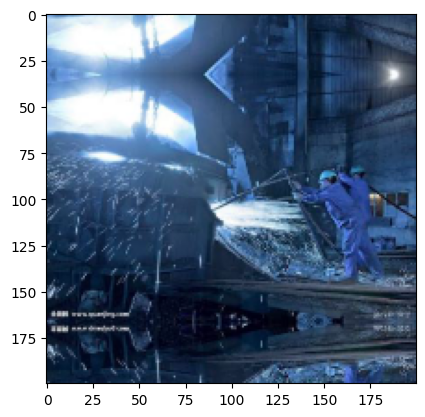

In [ ]:
plt.imshow(images[5]);

In [ ]:
print(images.shape)
print(labels.head(5))

(631, 200, 200, 3)
   Label
0      1
1      1
2      1
3      1
4      1


The Label is in the one-hot encoded format, 1 represents the "With helmet" and 0 represents the "Without helmet"

* the labels are mapped to "with helmet" as "1" and "without helmet" as "0"

# **Exploratory Data Analysis**

In [ ]:
def plot_images(images,labels):
  num_classes=2                                                                  # Number of Classes
  categories=np.unique(labels)
  keys=dict(labels['Label'])                                                      # Obtaing the unique classes from y_train
  rows = 3                                                                        # Defining number of rows=3
  cols = 4                                                                        # Defining number of columns=4
  fig = plt.figure(figsize=(10, 8))                                               # Defining the figure size to 10x8
  for i in range(cols):
      for j in range(rows):
          random_index = np.random.randint(0, len(labels))                        # Generating random indices from the data and plotting the images
          ax = fig.add_subplot(rows, cols, i * rows + j + 1)                      # Adding subplots with 3 rows and 4 columns
          ax.imshow(images[random_index, :])                                      # Plotting the image
          ax.set_title(keys[random_index])
  plt.show()

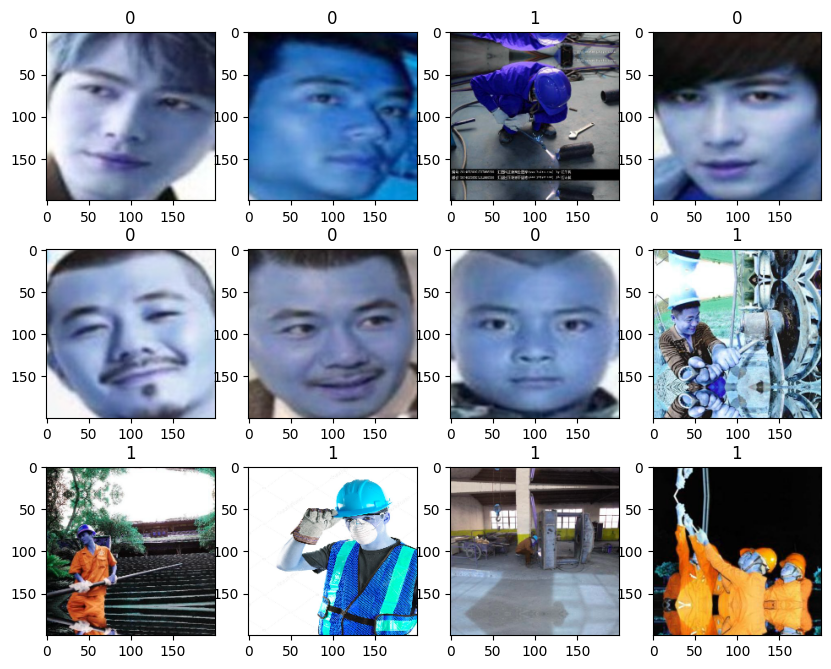

In [ ]:
plot_images(images,labels)

* By mapping random 12 images to its labels.
* I observe that images with helmet has label as 1
* The images without helmet has a label as 0

In [ ]:
print(labels['Label'].value_counts())

Label
0    320
1    311
Name: count, dtype: int64


    Helmet_Status
0          Helmet
1          Helmet
2          Helmet
3          Helmet
4          Helmet
..            ...
626     No Helmet
627     No Helmet
628     No Helmet
629     No Helmet
630     No Helmet

[631 rows x 1 columns]


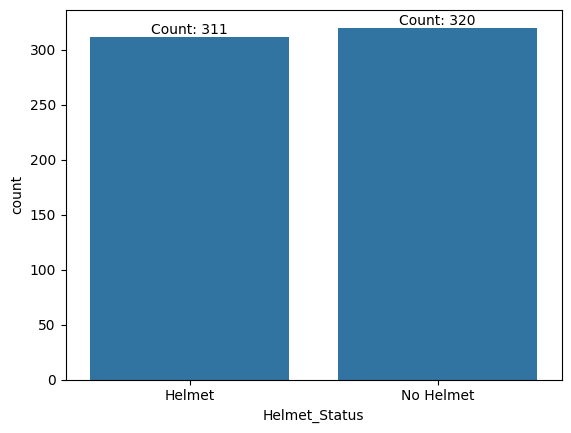

In [ ]:
# Proper counts (not booleans/DataFrames)
helmet = (labels['Label'] == 1).sum()      # e.g., 2
no_helmet = (labels['Label'] == 0).sum()   # e.g., 1

data = {
    'Helmet_Status': ['Helmet'] * helmet + ['No Helmet'] * no_helmet
}
labels1 = pd.DataFrame(data)
print(labels1)

# Correct countplot
sns.countplot(data=labels1, x='Helmet_Status')
plt.bar_label(plt.gca().containers[0], fmt='Count: %d')
plt.xticks(rotation='horizontal')
plt.show()


* By checking through the value count it seems both classes 0 and 1 are nearly equall so it is balanced dataset
* By checking through the count plot the dataset seems to be balanced
* we have 320 images with no helmet and 311 images with helmet

# **Data Pre-processing**

Convert the RGB images to Grayscale

In [ ]:
gray_images = []
for i in range(len(images)):
  gray_images.append(cv2.cvtColor(images[i], cv2.COLOR_RGB2GRAY))


images before and after converting it to grayscale

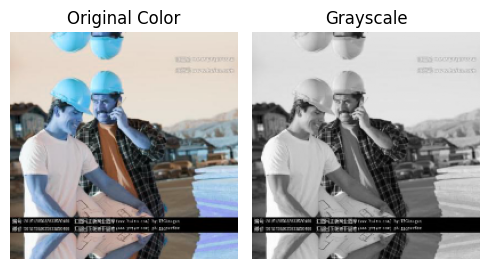

In [ ]:
n = 55
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(5, 5))

# Original color image
ax1.imshow(images[n])
ax1.set_title('Original Color')
ax1.axis('off')

# Grayscale version
ax2.imshow(gray_images[n], cmap='gray')
ax2.set_title('Grayscale')
ax2.axis('off')

plt.tight_layout()
plt.show()

Split the data into train, validation and test

In [ ]:
# Splitting the dataset into training (80%) and temporary (20%) sets
# stratify=labels ensures that class distribution is maintained in both sets
X_train_rgb, X_temp_rgb, y_train_rgb, y_temp_rgb = train_test_split(np.array(images),labels , test_size=0.2, random_state=42,stratify=labels)
# Splitting the temporary set further into validation (50%) and test (50%) sets
# This results in 10% validation and 10% test data from the original dataset
X_val_rgb, X_test_rgb, y_val_rgb, y_test_rgb = train_test_split(X_temp_rgb,y_temp_rgb, test_size=0.5, random_state=42,stratify=y_temp_rgb)

In [ ]:
# Splitting the dataset into training (80%) and temporary (20%) sets
# stratify=labels ensures that class distribution is maintained in both sets
X_train_gray, X_temp_gray, y_train_gray, y_temp_gray = train_test_split(np.array(gray_images),labels , test_size=0.2, random_state=42,stratify=labels)
# Splitting the temporary set further into validation (50%) and test (50%) sets
# This results in 10% validation and 10% test data from the original dataset
X_val_gray, X_test_gray, y_val_gray, y_test_gray = train_test_split(X_temp_gray,y_temp_gray , test_size=0.5, random_state=42,stratify=y_temp_gray)

In [ ]:
print("Number of rows in train data =", X_train_rgb.shape[0])
print("Number of rows in validation data =", X_val_rgb.shape[0])
print("Number of rows in test data =", X_test_rgb.shape[0])

Number of rows in train data = 504
Number of rows in validation data = 63
Number of rows in test data = 64


In [ ]:
print("Number of rows in train data =", X_train_gray.shape[0])
print("Number of rows in validation data =", X_val_gray.shape[0])
print("Number of rows in test data =", X_test_gray.shape[0])

Number of rows in train data = 504
Number of rows in validation data = 63
Number of rows in test data = 64


In [ ]:
print("X_train shape:", X_train_rgb.shape)  # Should be (N, 200, 200, 3)
print("y_train shape:", y_train_rgb.shape)  # Currently (N, 1)
print("y_train sample:", y_train_rgb[:5])

# After fix
print("y_train shape:", y_train_gray.shape)


X_train shape: (504, 200, 200, 3)
y_train shape: (504, 1)
y_train sample:      Label
83       1
202      1
176      1
404      0
427      0
y_train shape: (504, 1)


Normalization

In [ ]:
# Normalizing the image pixels
X_train_normalized = X_train_rgb.astype('float32')/255.0
X_val_normalized = X_val_rgb.astype('float32')/255.0
X_test_normalized = X_test_rgb.astype('float32')/255.0

In [ ]:
print("X_train_normalized shape:", X_train_normalized.shape)
print("X_val_normalized shape:", X_val_normalized.shape)
print("X_test_normalized shape:", X_test_normalized.shape)

X_train_normalized shape: (504, 200, 200, 3)
X_val_normalized shape: (63, 200, 200, 3)
X_test_normalized shape: (64, 200, 200, 3)


### **Utility functions**

In [ ]:
# defining a function to compute different metrics to check performance of a classification model built using statsmodels
def model_performance_classification(model, predictors, target):
    """
    Function to compute different metrics to check classification model performance

    model: classifier
    predictors: independent variables
    target: dependent variable
    """

    # checking which probabilities are greater than threshold
    pred = model.predict(predictors).reshape(-1)>0.5

    target = target.to_numpy().reshape(-1)


    acc = accuracy_score(target, pred)  # to compute Accuracy
    recall = recall_score(target, pred, average='weighted')  # to compute Recall
    precision = precision_score(target, pred, average='weighted')  # to compute Precision
    f1 = f1_score(target, pred, average='weighted')  # to compute F1-score

    # creating a dataframe of metrics
    df_perf = pd.DataFrame({"Accuracy": acc, "Recall": recall, "Precision": precision, "F1 Score": f1,},index=[0],)

    return df_perf

In [ ]:
def plot_confusion_matrix(model,predictors,target,ml=False):
    """
    Function to plot the confusion matrix

    model: classifier
    predictors: independent variables
    target: dependent variable
    ml: To specify if the model used is an sklearn ML model or not (True means ML model)
    """

    # checking which probabilities are greater than threshold
    pred = model.predict(predictors).reshape(-1)>0.5

    target = target.to_numpy().reshape(-1)

    # Plotting the Confusion Matrix using confusion matrix() function which is also predefined tensorflow module
    confusion_matrix = tf.math.confusion_matrix(target,pred)
    f, ax = plt.subplots(figsize=(10, 8))
    sns.heatmap(
        confusion_matrix,
        annot=True,
        linewidths=.4,
        fmt="d",
        square=True,
        ax=ax
    )
    plt.show()

# **When compiling the models with different optimizer and loss function to verify which optimizer and loss function gives better result**

* Optimizer as "Adam" with "learning_rate=0.01, momentum=0.2",
* loss_function as "categorical_crossentropy"
* Activation function as "sigmoid"
* The model reaches the accuracy nearly 52% on training data and 49% on validation data
* Thus the model seems to be overfit
---
* Optimizer as "SGD" with "learning_rate=0.01, momentum=0.2",
* loss_function as "categorical_crossentropy"
* Activation function as "sigmoid"
* The model reaches the accuracy nearly 52% on training data and 49% on validation data
* Thus the model seems to be overfit
* There is no difference between Adam optimizer and SGD optimizer
---
* Optimizer as "Adagrad" with "learning_rate=0.01, momentum=0.2",
* loss_function as "categorical_crossentropy"
* Activation function as "sigmoid"
* The model reaches the accuracy nearly 52% on training data and 49% on validation data
* Thus the model seems to be overfit
* There is no difference between Adam optimizer, SGD optimizer,Adagrad optimizer
---
#**Lets check the performance of the model by changing the loss function and activation layer**

* Optimizer as "Adagrad" with "learning_rate=0.01, momentum=0.2",
* loss_function as "binary_crossentropy"
* Activation function as "Sigmoid"
* The model reaches the accuracy nearly 98% on training data and 94% on validation data
* There is a difference between the model performance after using "loss_function as binary_crossentropy" and "Activation function as sigmoid"
---


Since the models gives the best performance on using
* Activation function as Sigmoid
* Loss function as binary_crossentropy on Adamax optimizer


Thus in the upcoming every models
 * Activation function will be sigmoid
 * loss function will be binary_crossentropy
 * Optimizer will be Adamax

# Model 1: Simple Convolutional Neural Network (CNN)

In [ ]:
# Fixing the seed for random number generators
import random
np.random.seed(42)
random.seed(42)
tf.random.set_seed(42)

In [ ]:
tf.keras.backend.clear_session()
model = Sequential()
model.add(Conv2D(64, (3, 3), activation='relu', padding="same", input_shape=(200, 200, 3)))
model.add(MaxPooling2D((2, 2), padding='same'))
model.add(Conv2D(32, (3, 3), activation='relu', padding="same"))
model.add(MaxPooling2D((2, 2), padding='same'))
model.add(Conv2D(32, (3, 3), activation='relu', padding="same"))
model.add(MaxPooling2D((2, 2), padding='same'))
model.add(Flatten())
model.add(Dense(100, activation='relu'))
model.add(Dense(1, activation='sigmoid'))
opt = tf.keras.optimizers.Adamax(learning_rate=0.01)
model.compile(optimizer=opt, loss='binary_crossentropy', metrics=['accuracy'])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 200, 200, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 100, 100, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 100, 100, 32)   │        18,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 50, 50, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 50, 50, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 25, 25, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 20000)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 100)            │     2,000,100 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           101 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,029,705 (7.74 MB)

 Trainable params: 2,029,705 (7.74 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 4s 123ms/step - accuracy: 0.5114 - loss: 0.0000e+00 - val_accuracy: 0.5066 - val_loss: 0.0000e+00
Epoch 2/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 75ms/step - accuracy: 0.5114 - loss: 0.0000e+00 - val_accuracy: 0.5066 - val_loss: 0.0000e+00
Epoch 3/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 75ms/step - accuracy: 0.5114 - loss: 0.0000e+00 - val_accuracy: 0.5066 - val_loss: 0.0000e+00
Epoch 4/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 75ms/step - accuracy: 0.5114 - loss: 0.0000e+00 - val_accuracy: 0.5066 - val_loss: 0.0000e+00
Epoch 5/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 75ms/step - accuracy: 0.5114 - loss: 0.0000e+00 - val_accuracy: 0.5066 - val_loss: 0.0000e+00
Epoch 6/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 74ms/step - accuracy: 0.5114 - loss: 0.0000e+00 - val_accuracy: 0.5066 - val_loss: 0.0000e+00
Epoch 7/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 75ms/step - accuracy: 0.5114 - loss: 0.0000e+00 - val_accuracy: 0.5066 - val_loss: 0.0000e+00
Epoch 8/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 78ms/step - accuracy: 0.5114 

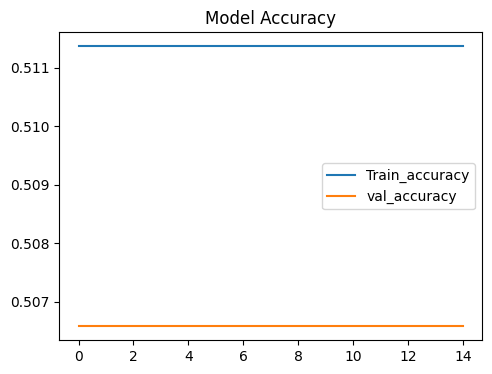

In [ ]:
history = model.fit(
    X_train_rgb, y_train_rgb,
    epochs=15,
    batch_size=50,
    validation_split=0.3
)

plt.figure(figsize=(12,4))
plt.subplot(1,2,1)
plt.plot(history.history['accuracy'], label='Train_accuracy')
plt.plot(history.history['val_accuracy'], label='val_accuracy')
plt.title('Model Accuracy')
plt.legend()
plt.show()


Epoch 1/15
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 72ms/step - accuracy: 0.5079 - loss: 0.0000e+00
Epoch 2/15
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step - accuracy: 0.5079 - loss: 0.0000e+00
Epoch 3/15
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step - accuracy: 0.5079 - loss: 0.0000e+00
Epoch 4/15
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step - accuracy: 0.5079 - loss: 0.0000e+00
Epoch 5/15
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step - accuracy: 0.5079 - loss: 0.0000e+00
Epoch 6/15
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step - accuracy: 0.5079 - loss: 0.0000e+00
Epoch 7/15
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step - accuracy: 0.5079 - loss: 0.0000e+00
Epoch 8/15
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step - accuracy: 0.5079 - loss: 0.0000e+00
Epoch 9/15
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step - accuracy: 0.5079 - loss: 0.0000e+00
Epoch 10/15
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step - accuracy: 0.5079 - loss: 0.0000e+00
Epoch 11/15
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step - accuracy: 0.5079 - loss: 0.0000e+00
Epoch 12/15
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 4

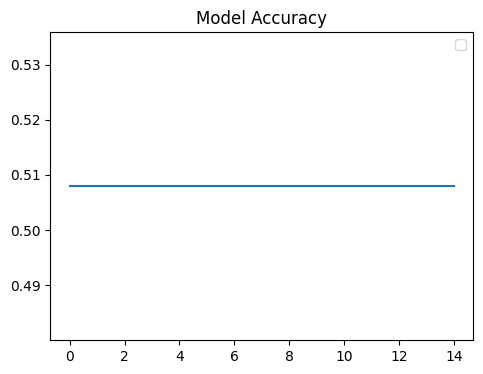

In [ ]:
historyv = model.fit(
    X_val_rgb, y_val_rgb,
    epochs=15,
    batch_size=50,
)

plt.figure(figsize=(12,4))
plt.subplot(1,2,1)
plt.plot(historyv.history['accuracy'])
plt.title('Model Accuracy')
plt.legend()
plt.show()


In [ ]:
History_Train = model_performance_classification(model, X_train_normalized,y_train_rgb)

print("Train performance metrics")
print(History_Train)

History_Validation = model_performance_classification(model, X_val_normalized,y_val_rgb)

print("Validation performance metrics")
print(History_Validation)

16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 28ms/step
Train performance metrics
   Accuracy    Recall  Precision  F1 Score
0  0.509921  0.509921   0.750576  0.346592
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step
Validation performance metrics
   Accuracy    Recall  Precision  F1 Score
0  0.507937  0.507937   0.257999  0.342189


Let check the performance of the model on gray scale images

In [ ]:
tf.keras.backend.clear_session()
modell = Sequential()
modell.add(Conv2D(64, (3, 3), activation='relu', padding="same", input_shape=(200, 200, 1)))
modell.add(MaxPooling2D((2, 2), padding='same'))
modell.add(Conv2D(32, (3, 3), activation='relu', padding="same"))
modell.add(MaxPooling2D((2, 2), padding='same'))
modell.add(Conv2D(32, (3, 3), activation='relu', padding="same"))
modell.add(MaxPooling2D((2, 2), padding='same'))
modell.add(Flatten())
modell.add(Dense(100, activation='relu'))
modell.add(Dense(1, activation='sigmoid'))
opt = tf.keras.optimizers.Adamax(learning_rate=0.01)
modell.compile(optimizer=opt, loss='binary_crossentropy', metrics=['accuracy'])
modell.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 200, 200, 64)   │           640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 100, 100, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 100, 100, 32)   │        18,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 50, 50, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 50, 50, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 25, 25, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 20000)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 100)            │     2,000,100 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           101 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,028,553 (7.74 MB)

 Trainable params: 2,028,553 (7.74 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 2s 106ms/step - accuracy: 0.5085 - loss: 0.0000e+00 - val_accuracy: 0.5066 - val_loss: 0.0000e+00
Epoch 2/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 69ms/step - accuracy: 0.5085 - loss: 0.0000e+00 - val_accuracy: 0.5066 - val_loss: 0.0000e+00
Epoch 3/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 68ms/step - accuracy: 0.5085 - loss: 0.0000e+00 - val_accuracy: 0.5066 - val_loss: 0.0000e+00
Epoch 4/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 83ms/step - accuracy: 0.5085 - loss: 0.0000e+00 - val_accuracy: 0.5066 - val_loss: 0.0000e+00
Epoch 5/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 83ms/step - accuracy: 0.5085 - loss: 0.0000e+00 - val_accuracy: 0.5066 - val_loss: 0.0000e+00
Epoch 6/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 84ms/step - accuracy: 0.5085 - loss: 0.0000e+00 - val_accuracy: 0.5066 - val_loss: 0.0000e+00
Epoch 7/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 82ms/step - accuracy: 0.5085 - loss: 0.0000e+00 - val_accuracy: 0.5066 - val_loss: 0.0000e+00
Epoch 8/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 78ms/step - accuracy: 0.5085 

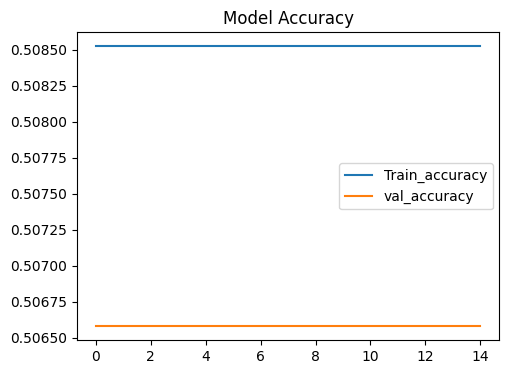

In [ ]:
history1G = modell.fit(
    X_train_gray, y_train_gray,
    epochs=15,
    batch_size=50,
    validation_split=0.3
)

plt.figure(figsize=(12,4))
plt.subplot(1,2,1)
plt.plot(history1G.history['accuracy'], label='Train_accuracy')
plt.plot(history1G.history['val_accuracy'], label='val_accuracy')
plt.title('Model Accuracy')
plt.legend()
plt.show()


Epoch 1/15
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step - accuracy: 0.5079 - loss: 0.0000e+00
Epoch 2/15
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step - accuracy: 0.5079 - loss: 0.0000e+00
Epoch 3/15
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step - accuracy: 0.5079 - loss: 0.0000e+00
Epoch 4/15
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step - accuracy: 0.5079 - loss: 0.0000e+00
Epoch 5/15
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step - accuracy: 0.5079 - loss: 0.0000e+00
Epoch 6/15
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step - accuracy: 0.5079 - loss: 0.0000e+00
Epoch 7/15
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step - accuracy: 0.5079 - loss: 0.0000e+00
Epoch 8/15
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step - accuracy: 0.5079 - loss: 0.0000e+00
Epoch 9/15
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step - accuracy: 0.5079 - loss: 0.0000e+00
Epoch 10/15
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step - accuracy: 0.5079 - loss: 0.0000e+00
Epoch 11/15
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step - accuracy: 0.5079 - loss: 0.0000e+00
Epoch 12/15
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 4

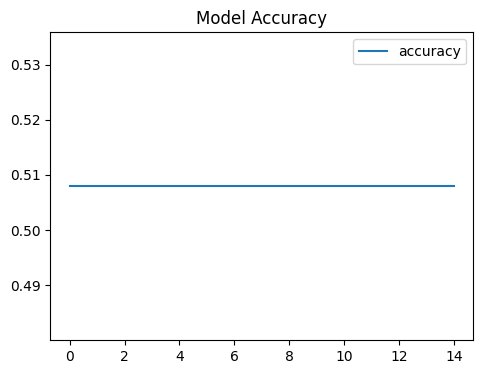

In [ ]:
history1G = modell.fit(
    X_val_gray, y_val_gray,
    epochs=15,
    batch_size=50,
)

plt.figure(figsize=(12,4))
plt.subplot(1,2,1)
plt.plot(history1G.history['accuracy'], label='accuracy')
plt.title('Model Accuracy')
plt.legend()
plt.show()


The base convolution model perform good on RGB image and Greyscale image

# **VGG - 16 Model**

In [ ]:
vgg_model = VGG16(weights='imagenet',include_top=False,input_shape=(200,200,3))
vgg_model.summary()

# Making all the layers of the VGG model non-trainable. i.e. freezing them
for layer in vgg_model.layers:
    layer.trainable = False

tf.keras.backend.clear_session()
model_1 = Sequential()

# Adding the convolutional part of the VGG16 model from above
model_1.add(vgg_model)

# Flattening the output of the VGG16 model because it is from a convolutional layer
model_1.add(Flatten())

# Adding a dense output layer
model_1.add(Dense(1, activation='sigmoid'))

opt=tf.keras.optimizers.Adamax(learning_rate=0.01)

# Compile model
model_1.compile(optimizer=opt, loss='binary_crossentropy', metrics=['accuracy'])
model_1.summary()


train_datagen = ImageDataGenerator()
history_vgg16 = model_1.fit(train_datagen.flow(X_train_normalized,y_train_rgb,
                                       batch_size=28,
                                       seed=42,
                                       shuffle=False),
                    epochs=20,
                    validation_data=(X_val_normalized,y_val_rgb),
                     )

# Generating the summary of the model
model_1.summary()

Model: "vgg16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 200, 200, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 200, 200, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 200, 200, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 100, 100, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 100, 100, 128)  │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 100, 100, 128)  │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 50, 50, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 50, 50, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 50, 50, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 50, 50, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 25, 25, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 25, 25, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 25, 25, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 25, 25, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 12, 12, 512)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 12, 12, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 12, 12, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 12, 12, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 6, 6, 512)      │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,714,688 (56.13 MB)

 Trainable params: 14,714,688 (56.13 MB)

 Non-trainable params: 0 (0.00 B)

...

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ vgg16 (Functional)              │ (None, 6, 6, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 18432)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │        18,433 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,769,989 (56.34 MB)

 Trainable params: 18,433 (72.00 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

 Optimizer params: 36,868 (144.02 KB)

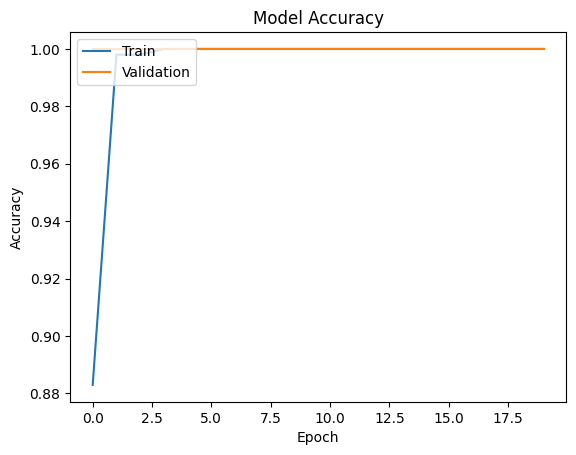

In [ ]:
plt.plot(history_vgg16.history['accuracy'])
plt.plot(history_vgg16.history['val_accuracy'])
plt.title('Model Accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='upper left')
plt.show()

In [ ]:
model_1_train_perf = model_performance_classification(model_1, X_train_normalized,y_train_rgb)

print("Train performance metrics")
print(model_1_train_perf)

16/16 ━━━━━━━━━━━━━━━━━━━━ 3s 147ms/step
Train performance metrics
   Accuracy  Recall  Precision  F1 Score
0       1.0     1.0        1.0       1.0


In [ ]:
model_1_val_perf = model_performance_classification(model_1, X_val_normalized,y_val_rgb)

print("Validation performance metrics")
print(model_1_val_perf)

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 161ms/step
Validation performance metrics
   Accuracy  Recall  Precision  F1 Score
0       1.0     1.0        1.0       1.0


16/16 ━━━━━━━━━━━━━━━━━━━━ 2s 130ms/step


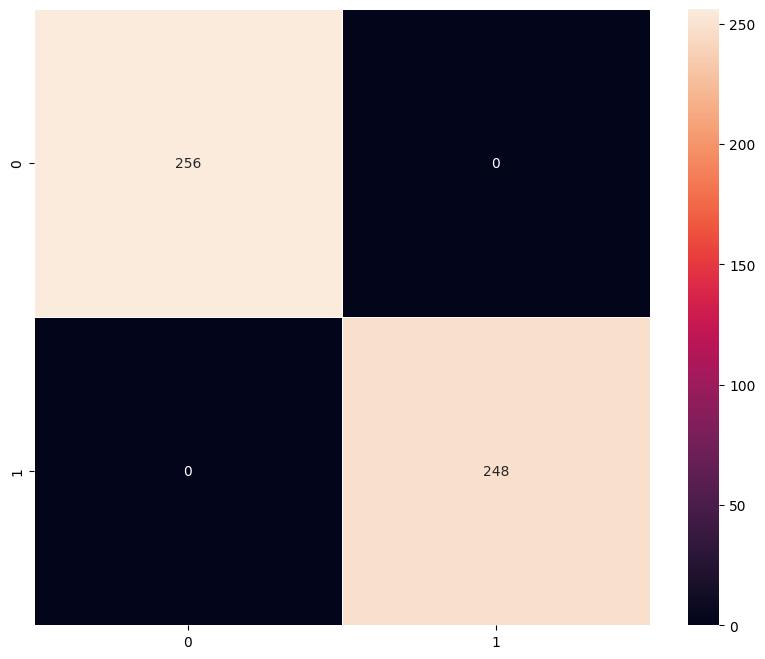

In [ ]:
plot_confusion_matrix(model_1,X_train_normalized,y_train_rgb)

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 146ms/step


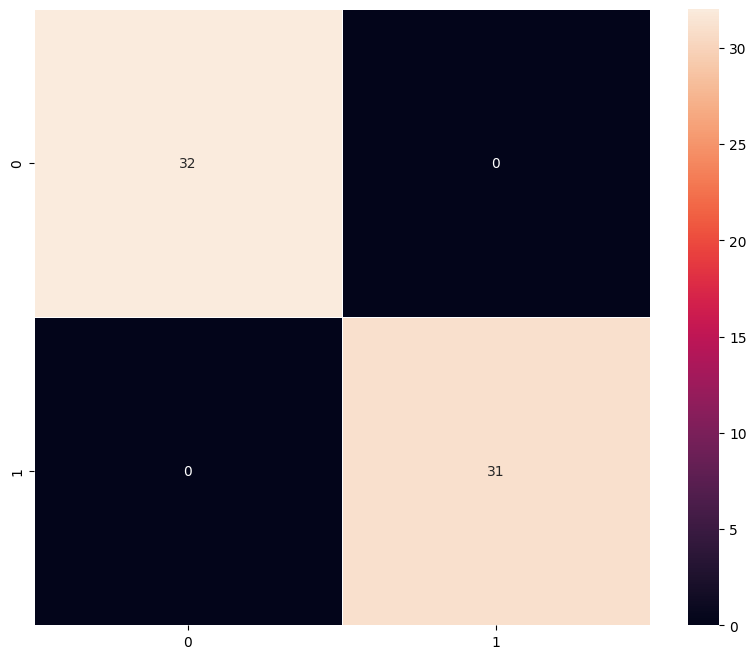

In [ ]:
plot_confusion_matrix(model_1,X_val_normalized,y_val_rgb)

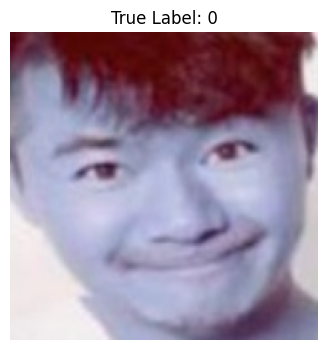

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 95ms/step
Predicted raw probability: 0.0000
Predicted class (threshold 0.5): 0
True Label (raw encoded): 0


In [ ]:
# Visualizing predicted and true labels (raw probabilities/classes)
n = 5
plt.figure(figsize=(4,4))
plt.imshow(X_val_rgb[n])
plt.title(f"True Label: {y_val_rgb.iloc[n]['Label']}")
plt.axis('off')
plt.show()

# Predict single image (batch dimension added and normalized)
single_image_normalized = X_val_normalized[n] # Use normalized data for prediction
prediction = model_1.predict(np.expand_dims(single_image_normalized, axis=0))[0][0]

print(f"Predicted raw probability: {prediction:.4f}")
print(f"Predicted class (threshold 0.5): {int(prediction > 0.5)}")
print(f"True Label (raw encoded): {y_val_rgb.iloc[n]['Label']}")

# **VGG-16 Base + FFNN**

In [ ]:
tf.keras.backend.clear_session()
model_2 = Sequential()

# Adding the convolutional part of the VGG16 model from above
model_2.add(vgg_model)

# Flattening the output of the VGG16 model because it is from a convolutional layer
model_2.add(Flatten())

#Adding the Feed Forward neural network
model_2.add(Dense(256,activation='relu'))
model_2.add(Dropout(rate=0.4))
model_2.add(Dense(32,activation='relu'))

# Adding a dense output layer
model_2.add(Dense(1, activation='sigmoid'))

opt=tf.keras.optimizers.Adamax(learning_rate=0.01)

# Compile model
model_2.compile(optimizer=opt, loss='categorical_crossentropy', metrics=['accuracy'])

history1_vgg16 = model_2.fit(train_datagen.flow(X_train_normalized,y_train_rgb,
                                       batch_size=20,
                                       seed=42,
                                       shuffle=False),
                    epochs=15,
                    validation_data=(X_val_normalized,y_val_rgb),
                     )

Epoch 1/15
26/26 ━━━━━━━━━━━━━━━━━━━━ 6s 131ms/step - accuracy: 0.4960 - loss: 0.0000e+00 - val_accuracy: 0.5079 - val_loss: 0.0000e+00
Epoch 2/15
26/26 ━━━━━━━━━━━━━━━━━━━━ 3s 116ms/step - accuracy: 0.4921 - loss: 0.0000e+00 - val_accuracy: 0.5079 - val_loss: 0.0000e+00
Epoch 3/15
26/26 ━━━━━━━━━━━━━━━━━━━━ 3s 119ms/step - accuracy: 0.5099 - loss: 0.0000e+00 - val_accuracy: 0.5079 - val_loss: 0.0000e+00
Epoch 4/15
26/26 ━━━━━━━━━━━━━━━━━━━━ 3s 116ms/step - accuracy: 0.4901 - loss: 0.0000e+00 - val_accuracy: 0.5079 - val_loss: 0.0000e+00
Epoch 5/15
26/26 ━━━━━━━━━━━━━━━━━━━━ 3s 117ms/step - accuracy: 0.4861 - loss: 0.0000e+00 - val_accuracy: 0.5079 - val_loss: 0.0000e+00
Epoch 6/15
26/26 ━━━━━━━━━━━━━━━━━━━━ 3s 120ms/step - accuracy: 0.4861 - loss: 0.0000e+00 - val_accuracy: 0.5079 - val_loss: 0.0000e+00
Epoch 7/15
26/26 ━━━━━━━━━━━━━━━━━━━━ 3s 125ms/step - accuracy: 0.5000 - loss: 0.0000e+00 - val_accuracy: 0.5079 - val_loss: 0.0000e+00
Epoch 8/15
26/26 ━━━━━━━━━━━━━━━━━━━━ 3s 124ms/s

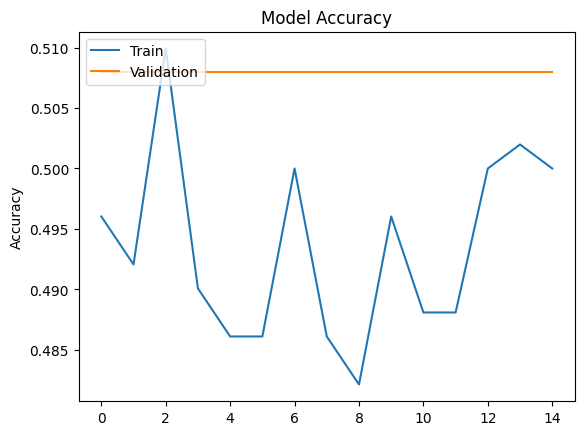

In [ ]:
plt.plot(history1_vgg16.history['accuracy'])
plt.plot(history1_vgg16.history['val_accuracy'])
plt.title('Model Accuracy')
plt.ylabel('Accuracy')
plt.legend(['Train', 'Validation'], loc='upper left')
plt.show()

In [ ]:
model_2_train_perf = model_performance_classification(model_2, X_train_normalized,y_train_rgb)

print("Train performance metrics")
print(model_2_train_perf)

model_2_val_perf = model_performance_classification(model_2, X_val_normalized,y_val_rgb)

print("Test performance metrics")
print(model_2_val_perf)

16/16 ━━━━━━━━━━━━━━━━━━━━ 3s 146ms/step
Train performance metrics
   Accuracy    Recall  Precision  F1 Score
0  0.507937  0.507937   0.257999  0.342189
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 151ms/step
Test performance metrics
   Accuracy    Recall  Precision  F1 Score
0  0.507937  0.507937   0.257999  0.342189


16/16 ━━━━━━━━━━━━━━━━━━━━ 2s 134ms/step


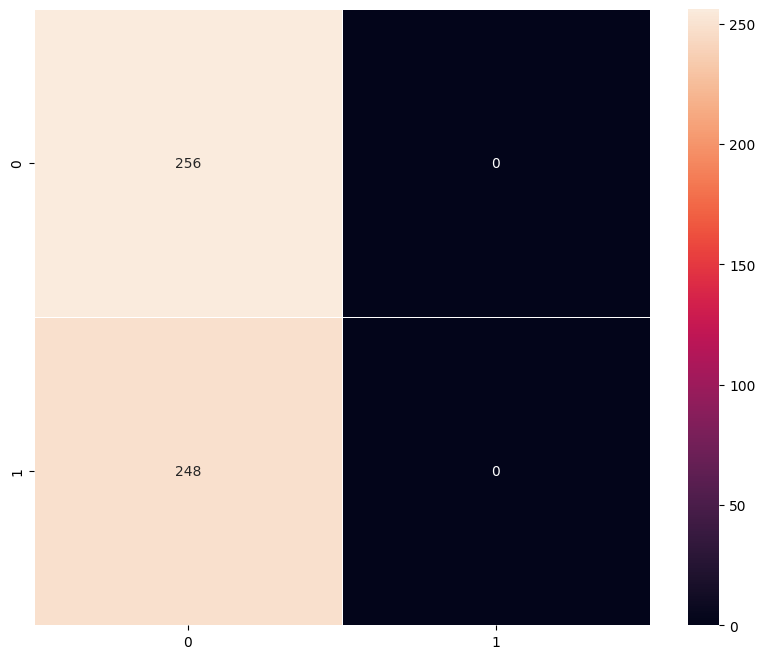

In [ ]:
plot_confusion_matrix(model_2,X_train_normalized,y_train_rgb)

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 151ms/step


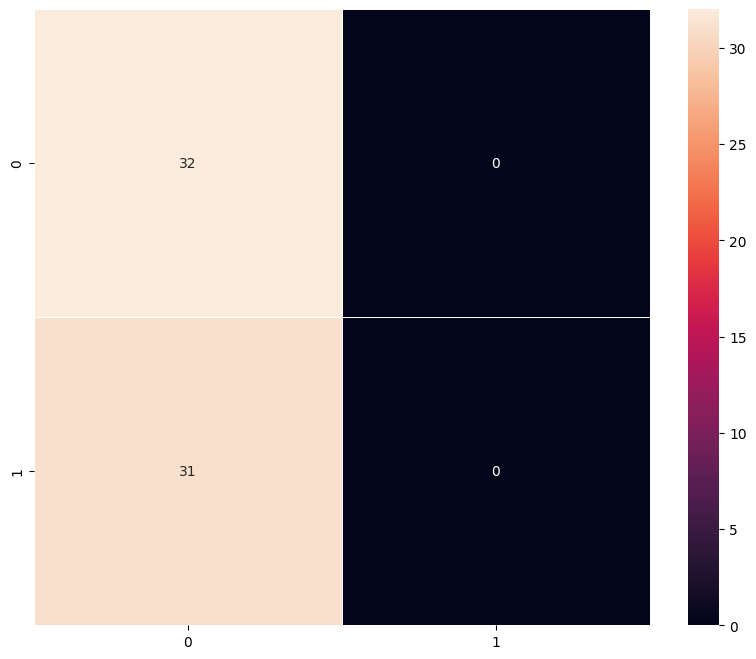

In [ ]:
plot_confusion_matrix(model_2,X_val_normalized,y_val_rgb)

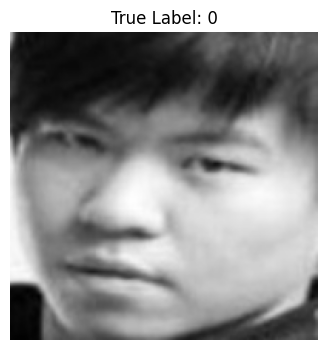

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 93ms/step
Predicted raw probability: 0.0000
Predicted class (threshold 0.5): 0
True Label (raw encoded): 0


In [ ]:
# Visualizing predicted and true labels (raw probabilities/classes)
n = 45
plt.figure(figsize=(4,4))
plt.imshow(X_val_rgb[n])
plt.title(f"True Label: {y_val_rgb.iloc[n]['Label']}")
plt.axis('off')
plt.show()

# Predict single image (batch dimension added and normalized)
single_image_normalized = X_val_normalized[n] # Use normalized data for prediction
prediction = model_1.predict(np.expand_dims(single_image_normalized, axis=0))[0][0]

print(f"Predicted raw probability: {prediction:.4f}")
print(f"Predicted class (threshold 0.5): {int(prediction > 0.5)}")
print(f"True Label (raw encoded): {y_val_rgb.iloc[n]['Label']}")

# **VGG - 16 with Base + FFNN + Data Augmentation**

In [ ]:
tf.keras.backend.clear_session()
model_3 = Sequential()

# Adding the convolutional part of the VGG16 model from above
model_3.add(vgg_model)

# Flattening the output of the VGG16 model because it is from a convolutional layer
model_3.add(Flatten())

#Adding the Feed Forward neural network
model_3.add(Dense(256,activation='relu'))
model_3.add(Dropout(rate=0.4))
model_3.add(Dense(32,activation='relu'))

# Adding a dense output layer
model_3.add(Dense(1, activation='sigmoid'))

model_3.compile(optimizer=Adam(), loss='binary_crossentropy', metrics=['accuracy'])

model_3.summary()

# Applying data augmentation
train_datagen = ImageDataGenerator(
                              rotation_range=20,
                              fill_mode='nearest',
                              width_shift_range=0.2,
                              height_shift_range=0.2,
                              shear_range=0.3,
                              zoom_range=0.4
                              )

history2_vgg16 = model_3.fit(train_datagen.flow(X_train_normalized,y_train_rgb,
                                       batch_size=28,
                                       seed=42,
                                       shuffle=False),
                    epochs=20,
                    verbose=1)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ vgg16 (Functional)              │ (None, 6, 6, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 18432)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │     4,718,848 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         8,224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 19,441,793 (74.16 MB)

 Trainable params: 4,727,105 (18.03 MB)

 Non-trainable params: 14,714,688 (56.13 MB)

Epoch 1/20
18/18 ━━━━━━━━━━━━━━━━━━━━ 9s 428ms/step - accuracy: 0.9087 - loss: 0.2379
Epoch 2/20
18/18 ━━━━━━━━━━━━━━━━━━━━ 9s 338ms/step - accuracy: 0.9960 - loss: 0.0102
Epoch 3/20
18/18 ━━━━━━━━━━━━━━━━━━━━ 7s 401ms/step - accuracy: 0.9960 - loss: 0.0167
Epoch 4/20
18/18 ━━━━━━━━━━━━━━━━━━━━ 6s 331ms/step - accuracy: 0.9901 - loss: 0.0219
Epoch 5/20
18/18 ━━━━━━━━━━━━━━━━━━━━ 8s 424ms/step - accuracy: 0.9940 - loss: 0.0153
Epoch 6/20
18/18 ━━━━━━━━━━━━━━━━━━━━ 6s 335ms/step - accuracy: 0.9881 - loss: 0.0532
Epoch 7/20
18/18 ━━━━━━━━━━━━━━━━━━━━ 8s 431ms/step - accuracy: 0.9960 - loss: 0.0125
Epoch 8/20
18/18 ━━━━━━━━━━━━━━━━━━━━ 6s 340ms/step - accuracy: 0.9901 - loss: 0.0161
Epoch 9/20
18/18 ━━━━━━━━━━━━━━━━━━━━ 8s 438ms/step - accuracy: 0.9940 - loss: 0.0257
Epoch 10/20
18/18 ━━━━━━━━━━━━━━━━━━━━ 9s 364ms/step - accuracy: 0.9960 - loss: 0.0235
Epoch 11/20
18/18 ━━━━━━━━━━━━━━━━━━━━ 7s 394ms/step - accuracy: 0.9980 - loss: 0.0125
Epoch 12/20
18/18 ━━━━━━━━━━━━━━━━━━━━ 6s 338ms/step

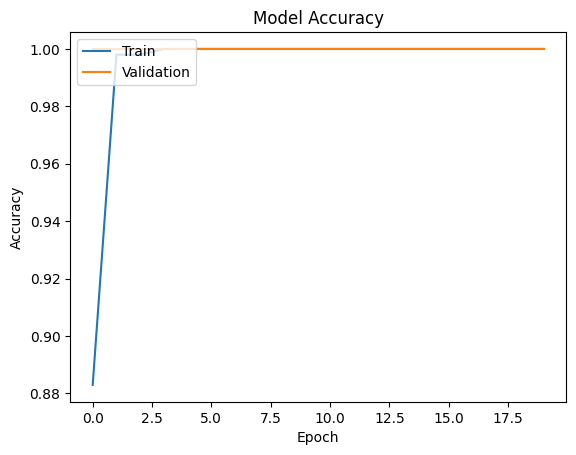

In [ ]:
plt.plot(history_vgg16.history['accuracy'])
plt.plot(history_vgg16.history['val_accuracy'])
plt.title('Model Accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='upper left')
plt.show()

In [ ]:
model_3_train_perf = model_performance_classification(model_3, X_train_normalized,y_train_rgb)

print("Train performance metrics")
print(model_3_train_perf)


model_3_val_perf = model_performance_classification(model_3, X_val_normalized,y_val_rgb)

print("Train performance metrics")
print(model_3_val_perf)

16/16 ━━━━━━━━━━━━━━━━━━━━ 3s 147ms/step
Train performance metrics
   Accuracy  Recall  Precision  F1 Score
0       1.0     1.0        1.0       1.0
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 153ms/step
Train performance metrics
   Accuracy  Recall  Precision  F1 Score
0       1.0     1.0        1.0       1.0


16/16 ━━━━━━━━━━━━━━━━━━━━ 2s 137ms/step


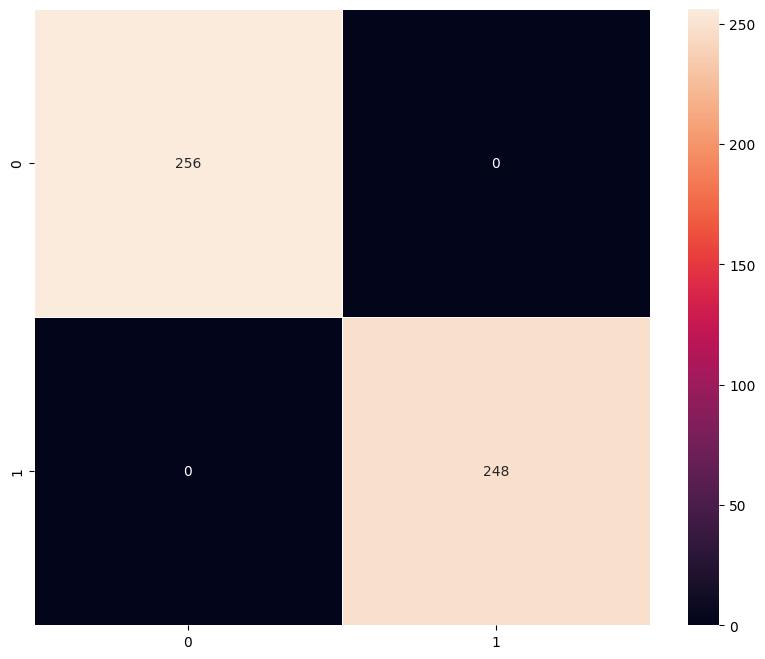

In [ ]:
plot_confusion_matrix(model_3,X_train_normalized,y_train_rgb)

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 153ms/step


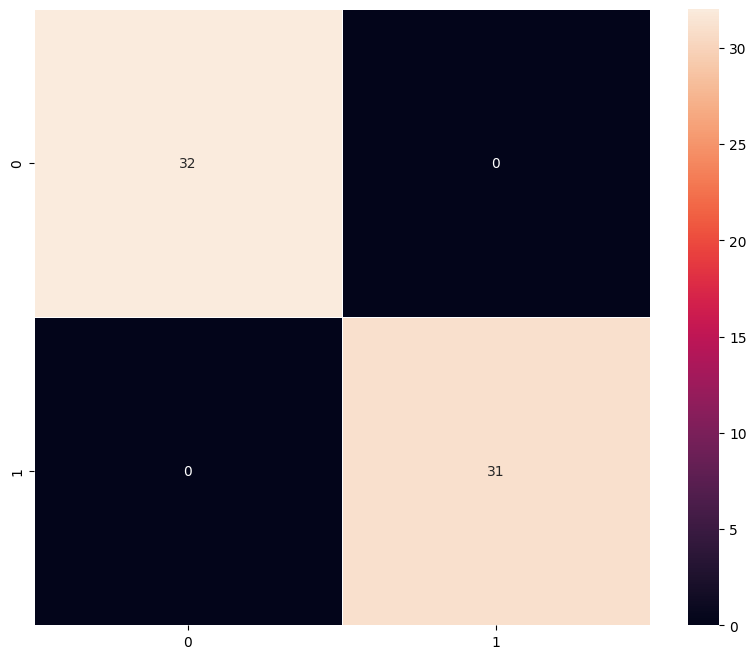

In [ ]:
plot_confusion_matrix(model_3,X_val_normalized,y_val_rgb)

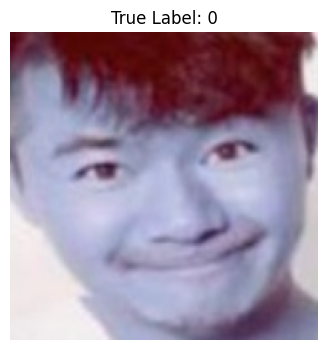

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 112ms/step
Predicted raw probability: 0.0000
Predicted class (threshold 0.5): 0
True Label (raw encoded): 0


In [ ]:
# Visualizing predicted and true labels (raw probabilities/classes)
n = 5
plt.figure(figsize=(4,4))
plt.imshow(X_val_rgb[n])
plt.title(f"True Label: {y_val_rgb.iloc[n]['Label']}")
plt.axis('off')
plt.show()

# Predict single image (batch dimension added and normalized)
single_image_normalized = X_val_normalized[n] # Use normalized data for prediction
prediction = model_1.predict(np.expand_dims(single_image_normalized, axis=0))[0][0]

print(f"Predicted raw probability: {prediction:.4f}")
print(f"Predicted class (threshold 0.5): {int(prediction > 0.5)}")
print(f"True Label (raw encoded): {y_val_rgb.iloc[n]['Label']}")

# **Model Performance Comparison and Final Model Selection**

In [ ]:
models_train_comp_df = pd.concat(
    [
        History_Train.T*100,
        model_1_train_perf.T*100,
        model_2_train_perf.T*100,
        model_3_train_perf.T*100,

    ],
    axis=1,
)
models_train_comp_df.columns = [
    "Base CNN with (Act = sigmoid & loss = categorical_crossentropy)",
    "VGG-16 Base (Act = Sigmoid & loss = binary_crossentropy)",
    "VGG-16 Base+FFNN (Act = sigmoid & loss = categorical_crossentropy)",
    "VGG-16 Base+FFNN+Data Aug (Act = Sigmoid & loss = binary_crossentropy)"
]

models_Val_comp_df = pd.concat(
    [
        History_Validation.T*100,
        model_1_val_perf.T*100,
        model_2_val_perf.T*100,
        model_3_val_perf.T*100,

    ],
    axis=1,
)
models_Val_comp_df.columns = [
 "Base CNN with (Act = sigmoid & loss = categorical_crossentropy)",
    "VGG-16 Base (Act = Sigmoid & loss = binary_crossentropy)",
    "VGG-16 Base+FFNN (Act = sigmoid & loss = categorical_crossentropy)",
    "VGG-16 Base+FFNN+Data Aug (Act = Sigmoid & loss = binary_crossentropy)"
]

In [ ]:
models_train_comp_df

,Base CNN with (Act = sigmoid & loss = categorical_crossentropy),VGG-16 Base (Act = Sigmoid & loss = binary_crossentropy),VGG-16 Base+FFNN (Act = sigmoid & loss = categorical_crossentropy),VGG-16 Base+FFNN+Data Aug (Act = Sigmoid & loss = binary_crossentropy)
Accuracy,50.992063,100.0,50.793651,100.0
Recall,50.992063,100.0,50.793651,100.0
Precision,75.057591,100.0,25.799950,100.0
F1 Score,34.659196,100.0,34.218881,100.0


In [ ]:
models_Val_comp_df

,Base CNN with (Act = sigmoid & loss = categorical_crossentropy),VGG-16 Base (Act = Sigmoid & loss = binary_crossentropy),VGG-16 Base+FFNN (Act = sigmoid & loss = categorical_crossentropy),VGG-16 Base+FFNN+Data Aug (Act = Sigmoid & loss = binary_crossentropy)
Accuracy,50.793651,100.0,50.793651,100.0
Recall,50.793651,100.0,50.793651,100.0
Precision,25.799950,100.0,25.799950,100.0
F1 Score,34.218881,100.0,34.218881,100.0


* VGG-16 (Base+FFNN+Augmentation) has achieved the highest performance on both the training and validation sets.

* Also, the difference between the training and validation scores for all models is very small, indicating that they have all generalized well.

* We will proceed with VGG-16 (Base+FFNN+Augmentation) as our final model

# **Let's check the models performence on unseen test data**

In [ ]:
Final_Selected_Model = model_performance_classification(model_3, X_test_normalized,y_test_rgb)

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 156ms/step


In [ ]:
Final_Selected_Model*100

,Accuracy,Recall,Precision,F1 Score
0,100.0,100.0,100.0,100.0


2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 156ms/step


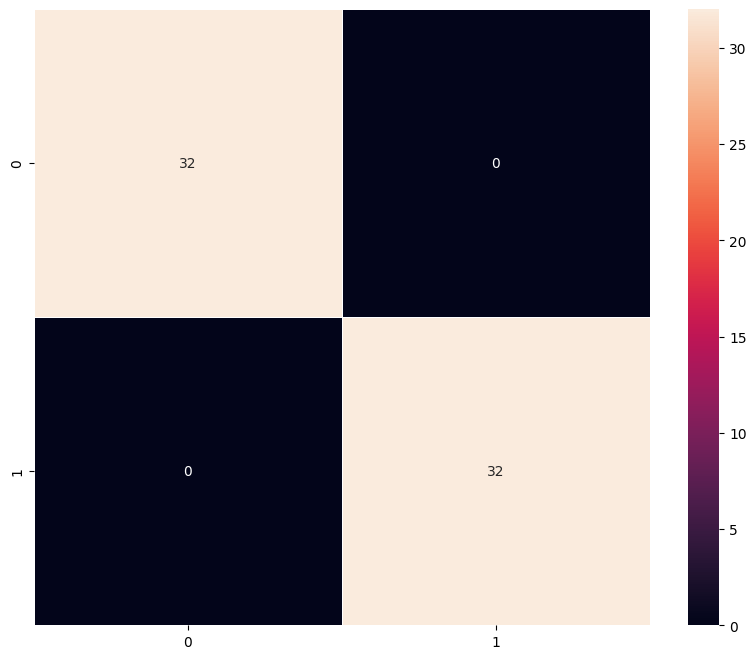

In [ ]:
plot_confusion_matrix(model_3, X_test_normalized,y_test_rgb)

# **Business Insights and Recommendations**

* The VGG-16 (Base) model performed well on the training data, achieving a train accuracy of ~0.94 and a validation F1-score of ~0.92. This indicates that the pre-trained features were quite valuable for this dataset.

* Adding a feed-forward neural network on top of the VGG-16 model significantly improved performance. This suggests that while the pre-trained features were beneficial, further refining them with an additional neural network tailored to our dataset enhanced the results.

* Although the performance of Model 3 is not on par with Models 1 and 2, it does not suffer from overfitting.

* These models can be further improved by training with different filter sizes and different number of filters.

* These models is be trained on the original image_size i.e 200 * 200.

* Data Augmentation can be performed more and dropout_rate can be changed to improve the model performance.

* Other Transfer Learning architectures can also be used to train the CNN model and these models can be used for classification.